## 1. Conexión con Google Drive
Se utiliza la función drive.mount() de la librería google.colab para conectar (montar) Google Drive, y así poder leer los archivos CSV directamente desde la carpeta donde están almacenados.

`drive.mount('/content/drive')`

In [68]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Carga de los datasets
Se utiliza la función read_csv() de la librería pandas para cargar cada archivo CSV como una tabla (DataFrame). Este mismo patrón se repite para los 8 archivos del dataset Olist.

`df_customers = pd.read_csv("ruta_del_archivo/olist_customers_dataset.csv")`

In [69]:
import pandas as pd

df_customers = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_customers_dataset.csv")
df_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [70]:
df_orders = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_orders_dataset.csv")
df_order_items = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_order_items_dataset.csv")
df_payments = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_order_payments_dataset.csv")
df_reviews = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_order_reviews_dataset.csv")
df_products = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_products_dataset.csv")
df_sellers = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_sellers_dataset.csv")
df_geolocation = pd.read_csv("/content/drive/MyDrive/TP FINAL AUSTRAL/olist_geolocation_dataset.csv")


print("Todo cargado ✅")

Todo cargado ✅


## 3. Exploración inicial
Se utilizan los atributos/funciones .shape y .isnull().sum() de pandas para conocer la cantidad de filas/columnas de cada tabla y detectar valores faltantes antes de cruzar los datos.

`df_orders.shape`
`df_orders.isnull().sum()`

In [71]:
print("=== ORDERS ===")
print(df_orders.shape)
print(df_orders.isnull().sum())
print()

print("=== ORDER ITEMS ===")
print(df_order_items.shape)
print(df_order_items.isnull().sum())

=== ORDERS ===
(99441, 8)
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

=== ORDER ITEMS ===
(112650, 7)
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


Se observan valores nulos esperables en algunas tablas: en reviews, la mayoría de los usuarios no deja título ni mensaje de reseña (solo puntaje); en products, 610 productos carecen de categoría y datos descriptivos. Estos nulos no requieren corrección, ya que representan información real (ausencia de dato) y no afectan los análisis agregados posteriores.

In [72]:
print("=== PAYMENTS ===")
print(df_payments.shape)
print(df_payments.isnull().sum())
print()

print("=== REVIEWS ===")
print(df_reviews.shape)
print(df_reviews.isnull().sum())
print()

print("=== PRODUCTS ===")
print(df_products.shape)
print(df_products.isnull().sum())
print()

print("=== SELLERS ===")
print(df_sellers.shape)
print(df_sellers.isnull().sum())
print()

print("=== GEOLOCATION ===")
print(df_geolocation.shape)
print(df_geolocation.isnull().sum())

=== PAYMENTS ===
(103886, 5)
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

=== REVIEWS ===
(99224, 7)
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

=== PRODUCTS ===
(32951, 9)
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

=== SELLERS ===
(3095, 4)
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

=== GEOLOCATION ===
(1000163, 5)
geolocation_zip_code_p

## 4. Conversión de fechas
Se utiliza la función to_datetime() de pandas para convertir las columnas de fecha (almacenadas como texto) al formato datetime, necesario para calcular tiempos de entrega y agrupar por mes.

`df_orders['order_purchase_timestamp'] = pd.to_datetime(df_orders['order_purchase_timestamp'])`

In [73]:
df_orders['order_purchase_timestamp'] = pd.to_datetime(df_orders['order_purchase_timestamp'])
df_orders['order_delivered_customer_date'] = pd.to_datetime(df_orders['order_delivered_customer_date'])
df_orders['order_estimated_delivery_date'] = pd.to_datetime(df_orders['order_estimated_delivery_date'])

print("Fechas convertidas ✅")
print(df_orders.dtypes)

Fechas convertidas ✅
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                        object
order_delivered_carrier_date             object
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


## 5. Unión de pedidos con clientes
Objetivo: la tabla de pedidos (orders) no contiene información de ubicación del cliente (ciudad, estado), esos datos están en la tabla de clientes (customers). Como varias preguntas del trabajo requieren analizar resultados por ciudad o por estado (por ejemplo, cantidad de usuarios por ciudad, ticket promedio por estado), es necesario combinar ambas tablas antes de poder responderlas.

Se utiliza la función merge() de pandas para combinar los pedidos con los datos de cliente, usando customer_id como clave de unión en común entre ambas tablas (equivalente a un BUSCARV/VLOOKUP de Excel).

`df_orders_customers = df_orders.merge(df_customers, on='customer_id', how='left')`

El resultado mantiene la misma cantidad de filas que la tabla de pedidos original (un pedido = un cliente), pero ahora incluye también las columnas de ubicación.

In [74]:
df_orders_customers = df_orders.merge(df_customers, on='customer_id', how='left')

print(df_orders_customers.shape)
df_orders_customers.head()

(99441, 12)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


## 6. Unión de ítems con productos y vendedores
Objetivo: la tabla de ítems (order_items) indica qué producto y qué vendedor participaron en cada venta, pero solo mediante códigos (product_id, seller_id) — no contiene la categoría del producto, sus medidas, ni la ubicación del vendedor. Para responder preguntas como "categoría más vendida por estado" o "producto más vendido", es necesario incorporar esos datos, que están en las tablas products y sellers.

Se encadenan dos llamadas a merge(): primero se combinan los ítems con la información del producto (por product_id), y luego el resultado se combina con la información del vendedor (por seller_id).

`df_items_full = df_order_items.merge(df_products, on='product_id', how='left')`
`df_items_full = df_items_full.merge(df_sellers, on='seller_id', how='left')`

El resultado mantiene la misma cantidad de filas que la tabla de ítems original (un ítem = un producto = un vendedor), pero ahora incluye también categoría, medidas del producto y ciudad/estado del vendedor.

In [75]:
df_items_full = df_order_items.merge(df_products, on='product_id', how='left')
df_items_full = df_items_full.merge(df_sellers, on='seller_id', how='left')

print(df_items_full.shape)
df_items_full.head()

(112650, 18)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,27277,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,3471,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,37564,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,14403,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,87900,loanda,PR


## 7. Tabla maestra
Se utiliza merge() nuevamente para unir las tablas anteriores (pedido+cliente con ítem+producto+vendedor) por order_id, generando una única tabla a nivel de ítem.

`df_master = df_orders_customers.merge(df_items_full, on='order_id', how='left')`

In [76]:
df_master = df_orders_customers.merge(df_items_full, on='order_id', how='left')

print(df_master.shape)
df_master.columns.tolist()

(113425, 29)


['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value',
 'product_category_name',
 'product_name_lenght',
 'product_description_lenght',
 'product_photos_qty',
 'product_weight_g',
 'product_length_cm',
 'product_height_cm',
 'product_width_cm',
 'seller_zip_code_prefix',
 'seller_city',
 'seller_state']

## 8. Pagos por pedido
Objetivo: la tabla de pagos (payments) puede tener más de una fila por pedido, ya que un cliente puede combinar varios métodos de pago en una misma compra (por ejemplo, voucher + tarjeta de crédito). Unirla directamente generaría filas duplicadas. Por eso, primero se resume la información de pago a nivel de pedido (un pedido = una fila), y luego se combina con los datos de pedido y cliente ya unidos en el paso 5.

Se utiliza groupby() junto con agg() para sumar el valor pagado de cada pedido (por si tuvo más de un método de pago) y quedarse con el primer método de pago registrado. Luego se utiliza merge() para combinar ese resultado con la tabla de pedidos y clientes, usando order_id como clave.

`df_payments_agg = df_payments.groupby('order_id').agg(payment_value=('payment_value', 'sum'), payment_type=('payment_type', 'first')).reset_index()`
`df_orders_payments = df_orders_customers.merge(df_payments_agg, on='order_id', how='left')`

Resultado: la tabla final (df_orders_payments) tiene 99.441 filas y 14 columnas, la misma cantidad de filas que la tabla original de pedidos — esto confirma que quedó correctamente a nivel de un pedido por fila, sin duplicados. Las columnas incluyen los datos del pedido (fechas, estado), del cliente (ciudad, estado, ID único) y del pago (valor total pagado y tipo de pago). Esta tabla es la base utilizada para responder las preguntas relacionadas con pagos, ticket promedio y cantidad de compras por usuario.

In [77]:
df_payments_agg = df_payments.groupby('order_id').agg(
    payment_value=('payment_value', 'sum'),
    payment_type=('payment_type', 'first')
).reset_index()

df_orders_payments = df_orders_customers.merge(df_payments_agg, on='order_id', how='left')

print(df_orders_payments.shape)
df_orders_payments.columns.tolist()

(99441, 14)


['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state',
 'payment_value',
 'payment_type']

## Pregunta 1: Cantidad de usuarios por ciudad
Objetivo: determinar en qué ciudades se concentra la mayor cantidad de clientes de Olist. Se agrupa por ciudad y estado en conjunto (no solo por ciudad), ya que en Brasil existen ciudades con el mismo nombre en distintos estados; agrupar solo por nombre de ciudad mezclaría datos de lugares distintos. Se utiliza customer_unique_id (identificador real de la persona) en lugar de customer_id (que cambia en cada pedido), para no contar al mismo cliente más de una vez.

`df_orders_payments.groupby(['customer_city', 'customer_state'])['customer_unique_id'].nunique()`

Resultado: São Paulo (SP) lidera ampliamente con 14.984 usuarios, seguida por Rio de Janeiro (RJ) con 6.620, Belo Horizonte (MG) con 2.672 y Brasília (DF) con 2.069. El orden coincide con el tamaño poblacional real de esas ciudades, lo cual valida la consistencia del dataset.

In [78]:
usuarios_por_ciudad = df_orders_payments.groupby(['customer_city', 'customer_state'])['customer_unique_id'].nunique().reset_index()
usuarios_por_ciudad = usuarios_por_ciudad.rename(columns={'customer_unique_id': 'cantidad_usuarios'})
usuarios_por_ciudad = usuarios_por_ciudad.sort_values('cantidad_usuarios', ascending=False)

usuarios_por_ciudad.head(10)

,customer_city,customer_state,cantidad_usuarios
3758,sao paulo,SP,14984
3281,rio de janeiro,RJ,6620
469,belo horizonte,MG,2672
587,brasilia,DF,2069
1187,curitiba,PR,1465
739,campinas,SP,1398
3080,porto alegre,RS,1326
3375,salvador,BA,1209
1587,guarulhos,SP,1153
3574,sao bernardo do campo,SP,908


## Pregunta 2: Cantidad de ítems comprados por estado
Objetivo: medir el volumen de productos vendidos en cada estado, no la cantidad de pedidos ni de clientes. Se utiliza la tabla a nivel de ítem (un pedido puede contener varios ítems), contando cada fila (cada ítem vendido).

`df_master.groupby('customer_state')['order_item_id'].count()`

Resultado: São Paulo concentra 47.449 ítems vendidos, muy por encima de Rio de Janeiro (14.579) y Minas Gerais (13.129). La distribución refleja el peso económico y poblacional de cada estado dentro de Brasil.

In [79]:
items_por_estado = df_master.groupby('customer_state')['order_item_id'].count().reset_index()
items_por_estado = items_por_estado.rename(columns={'order_item_id': 'cantidad_items'})
items_por_estado = items_por_estado.sort_values('cantidad_items', ascending=False)

items_por_estado.head(10)

,customer_state,cantidad_items
25,SP,47449
18,RJ,14579
10,MG,13129
22,RS,6235
17,PR,5740
23,SC,4176
4,BA,3799
6,DF,2406
8,GO,2333
7,ES,2256


## Pregunta 3: Producto más vendido por estado
Objetivo: identificar, para cada estado, cuál es el producto individual (por product_id) con mayor cantidad de unidades vendidas.

`df_master.groupby(['customer_state', 'product_id']).size().reset_index(name='cantidad')`

Resultado: en São Paulo el producto más vendido alcanzó 265 unidades. Un mismo producto (id d1c427060a0f73f6b889a5c7c61f2ac4) resultó ser el más vendido tanto en Rio de Janeiro (102 unidades) como en Minas Gerais (82 unidades), lo que sugiere que se trata de un producto de alta demanda a nivel regional, no solo local.

In [80]:
producto_por_estado = df_master.groupby(['customer_state', 'product_id']).size().reset_index(name='cantidad')
producto_top_por_estado = producto_por_estado.sort_values('cantidad', ascending=False).groupby('customer_state').head(1)
producto_top_por_estado = producto_top_por_estado.sort_values('cantidad', ascending=False)

producto_top_por_estado.head(10)

,customer_state,product_id,cantidad
54676,SP,aca2eb7d00ea1a7b8ebd4e68314663af,265
32530,RJ,d1c427060a0f73f6b889a5c7c61f2ac4,102
16299,MG,d1c427060a0f73f6b889a5c7c61f2ac4,82
35717,RS,422879e10f46682990de24d770e7f83d,42
24695,PR,a62e25e09e05e6faf31d90c6ec1aa3d1,28
39303,SC,368c6c730842d78016ad823897a372db,27
1352,BA,3dd2a17168ec895c781a9191c1e95ad7,24
4145,CE,bb50f2e236e5eea0100680137654686c,21
8865,GO,9571759451b1d780ee7c15012ea109d4,20
4983,DF,4c2394abfbac7ff59ec7a420918562fa,16


Adicionalmente, se incorpora la categoría de cada producto (product_category_name) mediante un merge() contra la tabla de productos, para que el resultado sea más legible que mostrar únicamente el código identificador (product_id).

`producto_top_por_estado = producto_top_por_estado.merge(df_products[['product_id', 'product_category_name']], on='product_id', how='left')`

In [81]:
producto_top_por_estado = producto_top_por_estado.merge(
    df_products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

producto_top_por_estado[['customer_state', 'product_id', 'product_category_name', 'cantidad']].head(10)

,customer_state,product_id,product_category_name,cantidad
0,SP,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,265
1,RJ,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,102
2,MG,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,82
3,RS,422879e10f46682990de24d770e7f83d,ferramentas_jardim,42
4,PR,a62e25e09e05e6faf31d90c6ec1aa3d1,relogios_presentes,28
5,SC,368c6c730842d78016ad823897a372db,ferramentas_jardim,27
6,BA,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,24
7,CE,bb50f2e236e5eea0100680137654686c,beleza_saude,21
8,GO,9571759451b1d780ee7c15012ea109d4,automotivo,20
9,DF,4c2394abfbac7ff59ec7a420918562fa,beleza_saude,16


## Pregunta 4: Categoría más vendida por estado
Objetivo: identificar la categoría de producto dominante en cada estado, para detectar patrones de consumo regional.

`df_master.groupby(['customer_state', 'product_category_name']).size().reset_index(name='cantidad')`

Resultado: la categoría cama_mesa_banho (ropa de cama, mesa y baño) domina en la mayoría de los estados principales (SP, RJ, MG, RS, GO). Se observan excepciones: en Paraná predomina moveis_decoracao (muebles/decoración), en Santa Catarina esporte_lazer (deporte/ocio), y en Bahía, Distrito Federal y Pernambuco beleza_saude (belleza/salud). Esto indica que, si bien hay una categoría dominante a nivel país, existen preferencias regionales distintas.

In [82]:
categoria_por_estado = df_master.groupby(['customer_state', 'product_category_name']).size().reset_index(name='cantidad')
categoria_top_por_estado = categoria_por_estado.sort_values('cantidad', ascending=False).groupby('customer_state').head(1)
categoria_top_por_estado = categoria_top_por_estado.sort_values('cantidad', ascending=False)

categoria_top_por_estado.head(10)

,customer_state,product_category_name,cantidad
1271,SP,cama_mesa_banho,5235
926,RJ,cama_mesa_banho,1644
483,MG,cama_mesa_banho,1331
1098,RS,cama_mesa_banho,614
898,PR,moveis_decoracao,520
1183,SC,esporte_lazer,363
136,BA,beleza_saude,350
252,DF,beleza_saude,246
753,PE,beleza_saude,240
371,GO,cama_mesa_banho,235


## Pregunta 5: Método de pago más usado por estado
Objetivo: identificar el método de pago predominante en cada estado, para evaluar si existen diferencias regionales en la forma de pago.

`df_orders_payments.groupby(['customer_state', 'payment_type']).size().reset_index(name='cantidad')`

Resultado: la tarjeta de crédito (credit_card) es el método de pago más utilizado en los 10 estados con mayor volumen de pedidos, sin excepción. Esto confirma que la tarjeta de crédito es el medio de pago dominante en el e-commerce brasileño, sin variaciones regionales relevantes entre los estados principales.

In [83]:
pago_por_estado = df_orders_payments.groupby(['customer_state', 'payment_type']).size().reset_index(name='cantidad')
pago_top_por_estado = pago_por_estado.sort_values('cantidad', ascending=False).groupby('customer_state').head(1)
pago_top_por_estado = pago_top_por_estado.sort_values('cantidad', ascending=False)

pago_top_por_estado.head(10)

,customer_state,payment_type,cantidad
98,SP,credit_card,31649
72,RJ,credit_card,10099
40,MG,credit_card,8892
86,RS,credit_card,3904
68,PR,credit_card,3705
90,SC,credit_card,2668
16,BA,credit_card,2590
24,DF,credit_card,1669
28,ES,credit_card,1552
32,GO,credit_card,1491


## Pregunta 6 (parte 0): Ticket promedio de compra total
Objetivo: calcular el valor promedio de un pedido considerando todo el dataset, como referencia general antes de abrir el análisis por estado y por ciudad.

Resultado: el ticket promedio es de R\$ 160,99, con un mínimo de R\$ 0,00 (pedidos pagados con voucher o con tipo de pago no definido) y un máximo de R\$ 13.664,08.

In [84]:
tickets_pedido = df_orders_payments['payment_value']

print(f"Ticket promedio total: R$ {tickets_pedido.mean():.2f}")
print(f"Ticket máximo: R$ {tickets_pedido.max():.2f}")
print(f"Ticket mínimo: R$ {tickets_pedido.min():.2f}")
print(f"Pedidos considerados: {tickets_pedido.count()}")

Ticket promedio total: R$ 160.99
Ticket máximo: R$ 13664.08
Ticket mínimo: R$ 0.00
Pedidos considerados: 99440


Resultado: los estados con mayor ticket promedio no son los de mayor volumen de ventas, sino estados del norte/noreste con menor cantidad de pedidos: Paraíba (PB, R\$ 264), Acre (AC, R\$ 243), Rondônia (RO, R\$ 241), Amapá (AP, R\$ 239) y Alagoas (AL, R\$ 235). Esto se explica porque, al estar más alejados de los centros de distribución, los costos de flete son mayores, elevando el valor promedio pagado por pedido.

In [85]:
ticket_por_estado = df_orders_payments.groupby('customer_state')['payment_value'].mean().reset_index()
ticket_por_estado = ticket_por_estado.rename(columns={'payment_value': 'ticket_promedio'})
ticket_por_estado = ticket_por_estado.sort_values('ticket_promedio', ascending=False)

ticket_por_estado.head(10)

,customer_state,ticket_promedio
14,PB,264.077836
0,AC,242.970617
20,RO,240.577866
3,AP,239.158824
1,AL,234.774964
13,PA,223.893179
26,TO,219.590464
16,PI,219.240343
21,RR,218.796087
24,SE,214.989286


## Pregunta 6 (parte 2): Ticket promedio por ciudad (sin filtrar)
Objetivo: calcular el ticket promedio a nivel de ciudad (además de estado), agrupando por ciudad y estado en conjunto para no mezclar ciudades homónimas de distintos estados.

Se utilizan groupby() y mean() de pandas para calcular el promedio de payment_value por combinación de ciudad y estado, y sort_values() para ordenar de mayor a menor.

`df_orders_payments.groupby(['customer_city', 'customer_state'])['payment_value'].mean()`

Resultado: esta primera versión mostró un problema — ciudades como Piancó (PB, $2.324,99) o São Sebastião (AL, $2.269,98) aparecían con tickets promedio muy superiores al resto. Al revisar, se detectó que estas ciudades tienen muy pocos pedidos registrados (a veces uno solo), por lo que un único pedido de alto valor "infla" artificialmente el promedio de toda la ciudad, sin ser representativo de un patrón real de consumo. Esto requiere un ajuste antes de poder usar este resultado (ver parte 3).

In [86]:
ticket_por_ciudad = df_orders_payments.groupby(['customer_city', 'customer_state'])['payment_value'].mean().reset_index()
ticket_por_ciudad = ticket_por_ciudad.rename(columns={'payment_value': 'ticket_promedio'})
ticket_por_ciudad = ticket_por_ciudad.sort_values('ticket_promedio', ascending=False)

ticket_por_ciudad.head(10)

,customer_city,customer_state,ticket_promedio
2928,pianco,PB,2324.99
3778,sao sebastiao,AL,2269.98
2588,nova esperanca do piria,PA,2252.66
1304,engenheiro navarro,MG,2106.55
32,agrestina,PE,2066.34
2317,mariental,PR,1867.85
2196,loreto,MA,1643.64
1663,ibitita,BA,1534.58
500,boa esperanca,RJ,1527.51
3011,pirpirituba,PB,1372.25


## Pregunta 6 (parte 3): Ticket promedio por ciudad (corregido, con filtro)
Objetivo: corregir la distorsión detectada en la parte 2, excluyendo del ranking las ciudades cuyo ticket promedio no es representativo por tener muy pocos pedidos.

Se calcula primero la cantidad de pedidos por ciudad con groupby() y size(). Ese resultado se combina mediante merge() con la tabla de ticket promedio por ciudad, y luego se filtra con una condición booleana, quedándose solo con las ciudades que tienen 10 o más pedidos. Por último, se ordena de mayor a menor ticket promedio.

`pedidos_por_ciudad = df_orders_payments.groupby(['customer_city', 'customer_state']).size().reset_index(name='cantidad_pedidos')`
`ticket_por_ciudad_filtrado = ticket_por_ciudad.merge(pedidos_por_ciudad, on=['customer_city', 'customer_state'])`
`ticket_por_ciudad_filtrado[ticket_por_ciudad_filtrado['cantidad_pedidos'] >= 10]`

Resultado: con el filtro aplicado, el ranking queda liderado por Taió (SC, $431,72 con 15 pedidos), Abaetetuba (PA, $424,75 con 11 pedidos) y Cícero Dantas (BA, $415,64 con 10 pedidos). Estos valores son mucho más confiables que los de la parte 2, ya que están respaldados por una cantidad mínima de pedidos y no dependen de un caso puntual aislado.

In [87]:
pedidos_por_ciudad = df_orders_payments.groupby(['customer_city', 'customer_state']).size().reset_index(name='cantidad_pedidos')

ticket_por_ciudad_filtrado = ticket_por_ciudad.merge(pedidos_por_ciudad, on=['customer_city', 'customer_state'])
ticket_por_ciudad_filtrado = ticket_por_ciudad_filtrado[ticket_por_ciudad_filtrado['cantidad_pedidos'] >= 10]
ticket_por_ciudad_filtrado = ticket_por_ciudad_filtrado.sort_values('ticket_promedio', ascending=False)

ticket_por_ciudad_filtrado.head(10)

,customer_city,customer_state,ticket_promedio,cantidad_pedidos
175,taio,SC,431.720000,15
183,abaetetuba,PA,424.751818,11
195,cicero dantas,BA,415.638000,10
207,campo formoso,BA,405.434000,10
224,balsas,MA,388.690000,17
225,gaspar,SC,387.787000,30
229,sobral,CE,386.353056,36
237,andradas,MG,382.997500,12
238,ariquemes,RO,382.280000,13
258,campo novo do parecis,MT,369.736250,16


## Pregunta 7 (parte 1): Cantidad de compras por usuario — ranking
Objetivo: identificar a los usuarios que realizaron más compras a lo largo del período analizado.

Se utilizan groupby() y nunique() de pandas para contar la cantidad de pedidos distintos (order_id) asociados a cada usuario (customer_unique_id), y sort_values() para ordenar de mayor a menor.

`df_orders_payments.groupby('customer_unique_id')['order_id'].nunique()`

Resultado: el usuario con más compras registró 17 en total, un caso claramente atípico. Le siguen usuarios con 9 y 7 compras. Estos valores, sin embargo, no representan el comportamiento general de la base de clientes — para eso se analiza la distribución completa en la parte 2.

In [88]:
compras_por_usuario = df_orders_payments.groupby('customer_unique_id')['order_id'].nunique().reset_index()
compras_por_usuario = compras_por_usuario.rename(columns={'order_id': 'cantidad_compras'})
compras_por_usuario = compras_por_usuario.sort_values('cantidad_compras', ascending=False)

compras_por_usuario.head(10)

,customer_unique_id,cantidad_compras
52973,8d50f5eadf50201ccdcedfb9e2ac8455,17
23472,3e43e6105506432c953e165fb2acf44c,9
37797,6469f99c1f9dfae7733b25662e7f1782,7
10354,1b6c7548a2a1f9037c1fd3ddfed95f33,7
76082,ca77025e7201e3b30c44b472ff346268,7
82883,dc813062e0fc23409cd255f7f53c7074,6
90451,f0e310a6839dce9de1638e0fe5ab282a,6
37585,63cfc61cee11cbe306bff5857d00bfe4,6
83540,de34b16117594161a6a89c50b289d35a,6
7175,12f5d6e1cbf93dafd9dcc19095df0b3d,6


## Pregunta 7 (parte 2): Cantidad de compras por usuario — distribución general
Objetivo: entender el comportamiento de recurrencia de toda la base de usuarios, no solo de los casos extremos vistos en la parte 1.

Se utiliza value_counts() de pandas sobre la columna de cantidad de compras, para contar cuántos usuarios compraron 1 vez, cuántos 2 veces, y así sucesivamente. sort_index() ordena el resultado de menor a mayor cantidad de compras, para que se lea como una progresión.

`compras_por_usuario['cantidad_compras'].value_counts().sort_index()`

Resultado: sobre un total aproximado de 96.096 usuarios únicos, 93.099 (alrededor del 97%) realizaron una sola compra. Solo 2.745 usuarios (2,9%) compraron 2 veces, y la cantidad cae abruptamente a partir de ahí: 203 usuarios con 3 compras, 30 con 4, 8 con 5, 6 con 6, 3 con 7, 1 con 9 y 1 con 17 (el caso atípico visto en la parte 1). Esto confirma una muy baja fidelización de clientes, comportamiento habitual en marketplaces donde cada compra puede corresponder a un vendedor distinto dentro de la plataforma.

In [89]:
compras_por_usuario['cantidad_compras'].value_counts().sort_index()

,count
cantidad_compras,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


## Pregunta 8: Ticket promedio por usuario
Objetivo: calcular cuánto gastó en promedio cada usuario a lo largo de todas sus compras.

Se utilizan groupby() y mean() de pandas para calcular el promedio de payment_value por usuario (customer_unique_id), y sort_values() para ordenar de mayor a menor.

`df_orders_payments.groupby('customer_unique_id')['payment_value'].mean()`

Resultado: el usuario con el ticket promedio más alto pagó $13.664,08. Considerando el hallazgo de la Pregunta 7 (la gran mayoría de los usuarios compra una sola vez), este valor corresponde probablemente a una única compra de alto valor — por ejemplo un mueble o electrodoméstico — y no a un cliente de alto valor recurrente. A diferencia del ticket promedio por ciudad (Pregunta 6), acá no hace falta aplicar ningún filtro: cada fila ya representa a un usuario individual, por lo que el promedio de un usuario con una sola compra es simplemente lo que pagó esa vez, sin riesgo de distorsión por mezclar datos de terceros.

In [90]:
ticket_por_usuario = df_orders_payments.groupby('customer_unique_id')['payment_value'].mean().reset_index()
ticket_por_usuario = ticket_por_usuario.rename(columns={'payment_value': 'ticket_promedio'})
ticket_por_usuario = ticket_por_usuario.sort_values('ticket_promedio', ascending=False)

ticket_por_usuario.head(10)

,customer_unique_id,ticket_promedio
3826,0a0a92112bd4c708ca5fde585afaa872,13664.08
44447,763c8b1c9c68a0229c42c9fc6f662b93,7274.88
82808,dc4802a71eae9be1dd28f5d788ceb526,6929.31
26205,459bef486812aa25204be022145caa62,6922.21
95806,ff4159b92c40ebe40454e3e6a7c35ed6,6726.66
24121,4007669dec559734d6f53e029e360987,6081.54
35070,5d0a2980b292d049061542014e8960bf,4809.44
89688,eebb5dda148d3893cdaf5b5ca3040ccb,4764.34
27441,48e1ac109decbb87765a3eade6854098,4681.78
89385,edde2314c6c30e864a128ac95d6b2112,4513.32


## Pregunta 9: Histórico de ingresos por estado
Objetivo: analizar la evolución de los ingresos de cada estado a lo largo del tiempo, mes a mes, para detectar tendencias o estacionalidad.

Primero se utiliza dt.to_period('M') para convertir la fecha de compra (que incluye día y hora) a su mes correspondiente, permitiendo agrupar por mes sin importar el día exacto. Luego se utilizan groupby() y sum() para calcular el total de ingresos (payment_value) por cada combinación de estado y mes — se usa sum() en lugar de mean(), ya que "ingresos" representa el total de dinero recaudado, no un promedio.

`df_orders_payments['mes_compra'] = df_orders_payments['order_purchase_timestamp'].dt.to_period('M')`
`df_orders_payments.groupby(['customer_state', 'mes_compra'])['payment_value'].sum()`

Resultado: se obtiene una tabla con los ingresos mensuales de cada estado. A modo de ejemplo, en el estado de Acre (AC) los ingresos fluctuaron entre un mínimo de $164,67 (marzo 2018) y un máximo de $2.382,64 (mayo 2017), sin una tendencia sostenida de crecimiento o caída, sino variaciones mes a mes. Esta tabla, además de responder la pregunta, sirve como base para construir un gráfico de evolución temporal de ingresos.

In [91]:
df_orders_payments['mes_compra'] = df_orders_payments['order_purchase_timestamp'].dt.to_period('M')

ingresos_por_estado_mes = df_orders_payments.groupby(['customer_state', 'mes_compra'])['payment_value'].sum().reset_index()
ingresos_por_estado_mes = ingresos_por_estado_mes.rename(columns={'payment_value': 'ingresos'})

ingresos_por_estado_mes.head(15)

,customer_state,mes_compra,ingresos
0,AC,2017-01,723.15
1,AC,2017-02,597.40
2,AC,2017-03,530.18
3,AC,2017-04,1351.51
4,AC,2017-05,2382.64
5,AC,2017-06,510.27
6,AC,2017-07,794.40
7,AC,2017-08,765.83
8,AC,2017-09,2029.23
9,AC,2017-10,958.17


## Pregunta 10: Top 5 productos más vendidos
Objetivo: identificar los 5 productos con mayor cantidad de unidades vendidas en todo el dataset, sin distinguir por estado.

Se utilizan groupby() y size() para contar cuántas veces se vendió cada producto (product_id) en total, y sort_values() junto con head(5) para quedarse con los 5 primeros. Por último, se utiliza merge() para incorporar la categoría de cada producto (product_category_name), de forma que el resultado sea más legible que mostrar únicamente el código identificador.

`df_master.groupby('product_id').size().reset_index(name='cantidad_vendida')`
`top5_productos = top5_productos.sort_values('cantidad_vendida', ascending=False).head(5)`
`top5_productos.merge(df_products[['product_id', 'product_category_name']], on='product_id', how='left')`

Resultado: el producto más vendido (categoría moveis_decoracao) alcanzó 527 unidades, seguido por uno de cama_mesa_banho (488 unidades) y tres productos de la categoría ferramentas_jardim (herramientas de jardín), con 484, 392 y 388 unidades respectivamente. Es llamativo que 3 de los 5 productos más vendidos pertenezcan a la misma categoría (ferramentas_jardim), lo que sugiere una demanda sostenida en ese rubro puntual, más allá de que cama_mesa_banho sea la categoría líder en volumen total (Pregunta 4).

In [92]:
top5_productos = df_master.groupby('product_id').size().reset_index(name='cantidad_vendida')
top5_productos = top5_productos.sort_values('cantidad_vendida', ascending=False).head(5)

top5_productos = top5_productos.merge(
    df_products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

top5_productos

,product_id,cantidad_vendida,product_category_name
0,aca2eb7d00ea1a7b8ebd4e68314663af,527,moveis_decoracao
1,99a4788cb24856965c36a24e339b6058,488,cama_mesa_banho
2,422879e10f46682990de24d770e7f83d,484,ferramentas_jardim
3,389d119b48cf3043d311335e499d9c6b,392,ferramentas_jardim
4,368c6c730842d78016ad823897a372db,388,ferramentas_jardim


## Gráfico 1: Cantidad de compras promedio por tipo de pago
Objetivo: comparar si el método de pago utilizado está asociado a una mayor o menor cantidad de compras por usuario (es decir, si algún método de pago se asocia a clientes más recurrentes).

Primero se calcula, para cada usuario, cuántas compras realizó con cada tipo de pago (agrupando por usuario y tipo de pago en conjunto). Luego se promedia ese resultado por tipo de pago. Se utiliza bar() de la librería matplotlib para graficar un gráfico de barras, con el tipo de pago en el eje X y la cantidad promedio de compras en el eje Y.

`compras_por_pago = df_orders_payments.groupby(['customer_unique_id', 'payment_type'])['order_id'].nunique().reset_index()`
`promedio_por_tipo_pago = compras_por_pago.groupby('payment_type')['order_id'].mean().reset_index()`
`plt.bar(promedio_por_tipo_pago['payment_type'], promedio_por_tipo_pago['compras_promedio'])`

Resultado: todos los métodos de pago muestran un promedio muy cercano a 1.0 compra por usuario, prácticamente sin diferencias entre ellos. Esto es consistente con el hallazgo de la Pregunta 7: como el 97% de los usuarios compra una sola vez, el tipo de pago utilizado no influye en la cantidad de compras — no hay ningún método asociado a mayor fidelización del cliente.

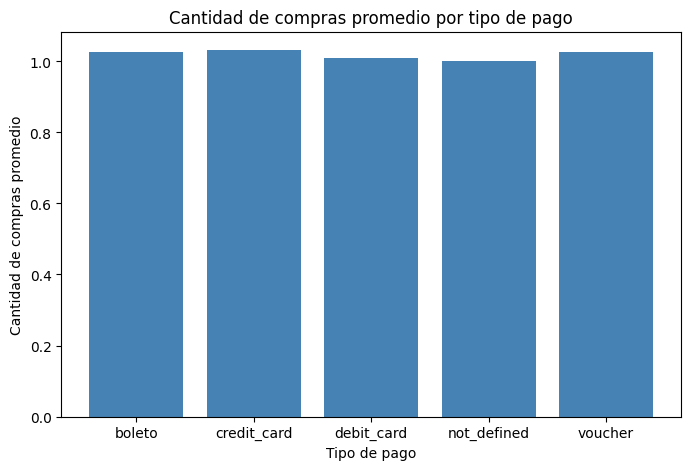

In [93]:
import matplotlib.pyplot as plt

compras_por_pago = df_orders_payments.groupby(['customer_unique_id', 'payment_type'])['order_id'].nunique().reset_index()
promedio_por_tipo_pago = compras_por_pago.groupby('payment_type')['order_id'].mean().reset_index()
promedio_por_tipo_pago = promedio_por_tipo_pago.rename(columns={'order_id': 'compras_promedio'})

plt.figure(figsize=(8,5))
plt.bar(promedio_por_tipo_pago['payment_type'], promedio_por_tipo_pago['compras_promedio'], color='steelblue')
plt.xlabel('Tipo de pago')
plt.ylabel('Cantidad de compras promedio')
plt.title('Cantidad de compras promedio por tipo de pago')
plt.show()

## Gráfico 1: Cantidad de compras promedio por tipo de pago (versión mejorada)
El objetivo del análisis es el mismo que en la versión anterior: comparar si el método de pago está asociado a una mayor o menor cantidad de compras por usuario. El cálculo tampoco cambia. Lo que se ajusta en esta versión es únicamente la visualización, mediante un escalado del eje Y.

En el primer gráfico, al graficar con el eje Y desde 0 (rango por defecto), las diferencias entre tipos de pago —que son de centésimas— resultaban imperceptibles: todas las barras se veían prácticamente iguales. Para solucionar esto, se utiliza plt.ylim(0.98, 1.05) para acotar el eje Y al rango donde efectivamente están los datos, y plt.text() para escribir el valor exacto arriba de cada barra como respaldo numérico.

`plt.ylim(0.98, 1.05)`
`plt.text(barra.get_x() + barra.get_width()/2, altura + 0.002, f'{altura:.3f}', ha='center')`

Nota metodológica: acotar el eje Y (en vez de arrancar en 0) permite visualizar diferencias pequeñas, pero también las hace parecer más grandes de lo que son en términos absolutos. Por eso se aclara explícitamente: la diferencia real entre métodos de pago es mínima (todos entre 1.00 y 1.03 compras promedio), y el escalado se aplicó solo con fines de legibilidad, no para exagerar el hallazgo.

Resultado: con el eje ajustado, se distingue que credit_card y voucher tienen el promedio ligeramente más alto (~1.03), mientras que not_defined tiene el más bajo (~1.00). Aun así, estas diferencias no son relevantes: como se vio en la Pregunta 7, el 97% de los usuarios compra una sola vez, por lo que el tipo de pago no influye realmente en la cantidad de compras.

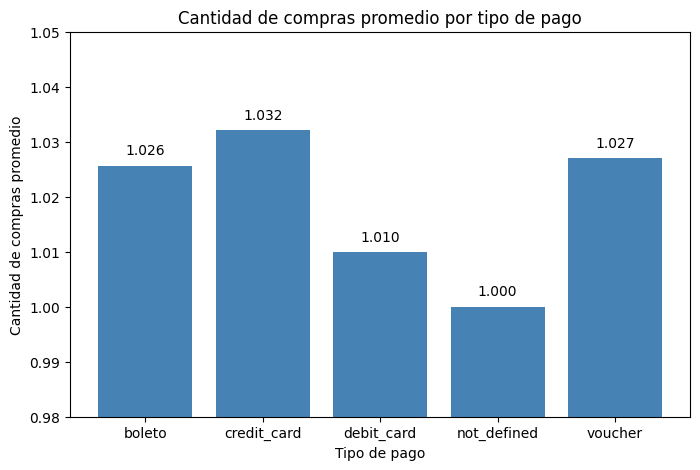

In [94]:
plt.figure(figsize=(8,5))
barras = plt.bar(promedio_por_tipo_pago['payment_type'], promedio_por_tipo_pago['compras_promedio'], color='steelblue')

for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, altura + 0.002, f'{altura:.3f}', ha='center')

plt.ylim(0.98, 1.05)
plt.xlabel('Tipo de pago')
plt.ylabel('Cantidad de compras promedio')
plt.title('Cantidad de compras promedio por tipo de pago')
plt.show()

## Gráfico 2: Usuarios por estado vs. Ventas por estado
Objetivo: analizar si existe una relación entre la cantidad de usuarios de cada estado y su cantidad de ventas, es decir, si los estados con más clientes son también los que más venden en proporción.

Se calculan por separado los usuarios únicos y las ventas (pedidos) de cada estado, y se combinan con merge(). Se utiliza scatter() de matplotlib para dibujar un punto por estado y annotate() para identificarlo.

Decisión de escala: en una primera versión con ejes normales, São Paulo (más de 40.000 usuarios) aplastaba al resto de los estados, que quedaban amontonados en una esquina y no se podían leer. Por eso se aplica escala logarítmica en ambos ejes con plt.xscale('log') y plt.yscale('log'): cada división del eje representa una multiplicación por 10, lo que permite ver estados muy chicos y muy grandes en el mismo gráfico. Hay que leerlo con cuidado, porque las distancias ya no son diferencias absolutas sino proporcionales.

Resultado: con la escala logarítmica, los 27 estados se distribuyen de forma legible, formando una línea casi perfecta desde Roraima (RR, el más chico) hasta São Paulo (SP, el más grande). La relación entre usuarios y ventas es prácticamente proporcional en todos los estados: ninguno se aparta del patrón, lo que sugiere que Olist vende de manera pareja en todo el territorio.

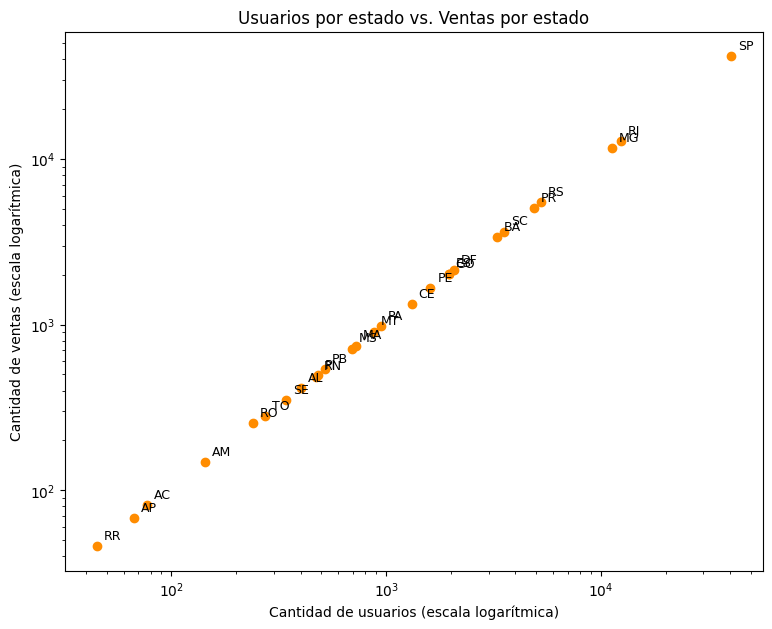

In [95]:
plt.figure(figsize=(9,7))
plt.scatter(usuarios_vs_ventas['cantidad_usuarios'], usuarios_vs_ventas['cantidad_ventas'], color='darkorange')

for i, row in usuarios_vs_ventas.iterrows():
    plt.annotate(row['customer_state'], (row['cantidad_usuarios'], row['cantidad_ventas']),
                 xytext=(5, 5), textcoords='offset points', fontsize=9)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Cantidad de usuarios (escala logarítmica)')
plt.ylabel('Cantidad de ventas (escala logarítmica)')
plt.title('Usuarios por estado vs. Ventas por estado')
plt.show()

## Gráfico propio 1: Tiempo de entrega real vs. previsto por estado
Por qué este gráfico: compara dos medidas (días reales y días prometidos) para las mismas categorías (estados). Las barras agrupadas permiten ver de un vistazo en qué estados la promesa de entrega es más exigente y cuánto margen deja Olist.

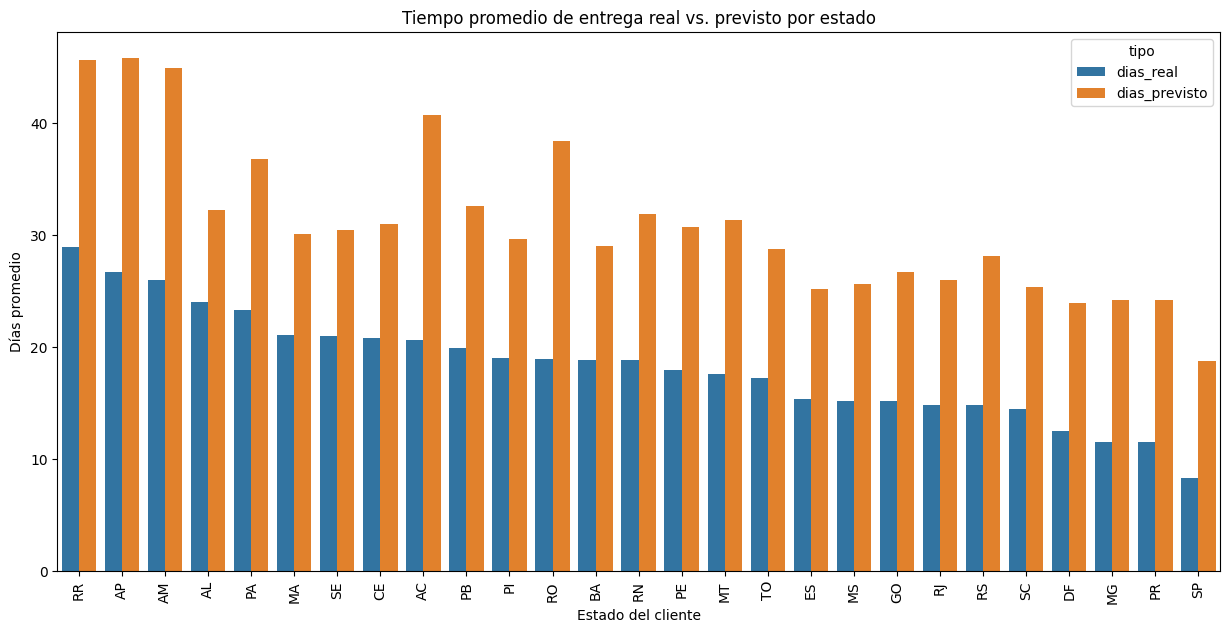

Adelanto promedio: 10.9 días | Entregados tarde: 8.1%


In [96]:
import seaborn as sns

entregas = df_orders_customers.dropna(subset=['order_delivered_customer_date']).copy()
entregas['dias_real'] = (entregas['order_delivered_customer_date'] - entregas['order_purchase_timestamp']).dt.days
entregas['dias_previsto'] = (entregas['order_estimated_delivery_date'] - entregas['order_purchase_timestamp']).dt.days

tiempos = entregas.groupby('customer_state')[['dias_real', 'dias_previsto']].mean().reset_index()
tiempos = tiempos.sort_values('dias_real', ascending=False)
tiempos_largo = tiempos.melt(id_vars='customer_state', var_name='tipo', value_name='dias')

plt.figure(figsize=(15, 7))
sns.barplot(x='customer_state', y='dias', hue='tipo', data=tiempos_largo)
plt.title('Tiempo promedio de entrega real vs. previsto por estado')
plt.xlabel('Estado del cliente')
plt.ylabel('Días promedio')
plt.xticks(rotation=90)
plt.show()

adelanto = (entregas['order_estimated_delivery_date'] - entregas['order_delivered_customer_date']).dt.days
print(f"Adelanto promedio: {adelanto.mean():.1f} días | Entregados tarde: {(adelanto < 0).mean()*100:.1f}%")

Resultado: en los 27 estados la entrega real fue más rápida que la prevista. En promedio, los pedidos llegan unos 10,9 días antes de lo estimado y solo el 8,1% llega tarde. Los estados con mayor tiempo de entrega son Roraima (RR), Amapá (AP) y Amazonas (AM), con más de 25 días, mientras que São Paulo (SP) es el más rápido, con unos 8 días. Esto muestra que Olist prevé plazos holgados, sobre todo para los estados más lejanos.

## Gráfico propio 2: Puntaje de reseña vs. puntualidad de la entrega
Por qué este gráfico: un heatmap es la forma más eficiente de ver la frecuencia conjunta de dos variables ordenadas (puntaje de 1 a 5 y franja de atraso o adelanto de la entrega). Muestra de inmediato en qué combinaciones se concentran los pedidos y permite comprobar si la puntualidad afecta la satisfacción del cliente.

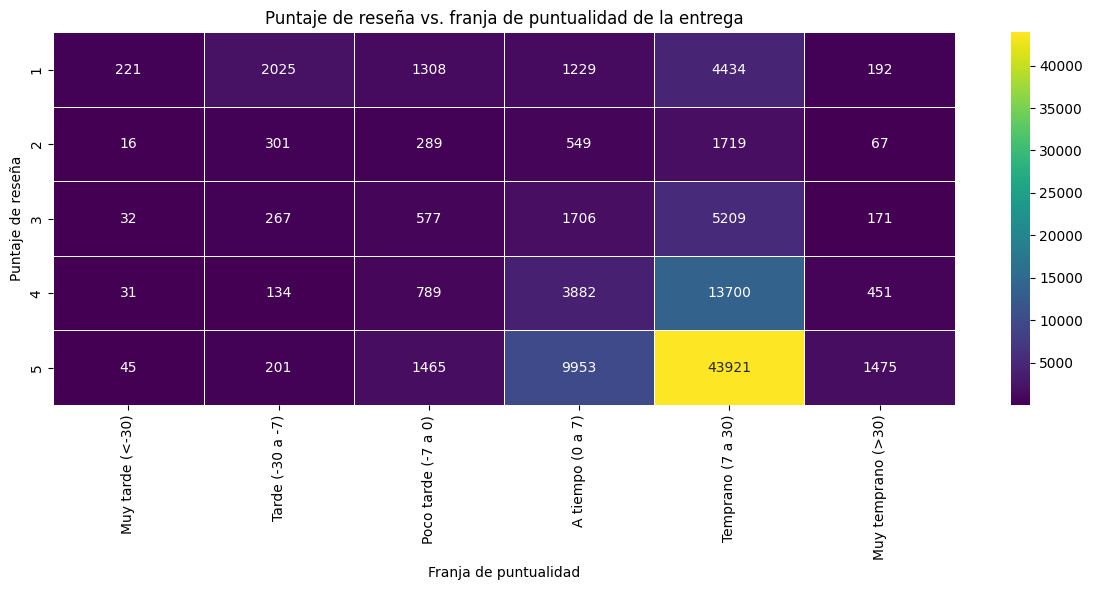

Correlación: 0.267


In [97]:
import numpy as np

df_rev = df_orders.merge(df_reviews, on='order_id', how='inner')
df_rev = df_rev.dropna(subset=['order_delivered_customer_date', 'review_score']).copy()
df_rev['dias_diferencia'] = (df_rev['order_estimated_delivery_date'] - df_rev['order_delivered_customer_date']).dt.days

cortes = [-np.inf, -30, -7, 0, 7, 30, np.inf]
etiquetas = ['Muy tarde (<-30)', 'Tarde (-30 a -7)', 'Poco tarde (-7 a 0)',
             'A tiempo (0 a 7)', 'Temprano (7 a 30)', 'Muy temprano (>30)']
df_rev['franja'] = pd.cut(df_rev['dias_diferencia'], bins=cortes, labels=etiquetas, right=False)

tabla_heat = df_rev.pivot_table(index='review_score', columns='franja', aggfunc='size', fill_value=0, observed=False)[etiquetas]

plt.figure(figsize=(12, 6))
sns.heatmap(tabla_heat, annot=True, fmt='d', cmap='viridis', linewidths=.5)
plt.title('Puntaje de reseña vs. franja de puntualidad de la entrega')
plt.xlabel('Franja de puntualidad')
plt.ylabel('Puntaje de reseña')
plt.tight_layout()
plt.show()

print(f"Correlación: {df_rev['review_score'].corr(df_rev['dias_diferencia']):.3f}")

Resultado: la puntualidad de la entrega influye en la satisfacción del cliente. Cuando el pedido llega tarde, entre el 69% y el 79% de las reseñas son de 1 o 2 estrellas; cuando llega a tiempo o antes de lo previsto, ese porcentaje baja a cerca del 10%. La correlación entre el puntaje y los días de adelanto es de 0,27 (positiva y moderada), por lo que la puntualidad es un factor importante pero no el único que explica la satisfacción.

## Gráfico propio 3: Ticket promedio por usuario por estado
Por qué este gráfico: completa las Preguntas 6 y 8 mostrando cómo varía el gasto promedio por cliente entre estados. Un gráfico de barras ordenado permite comparar los 27 estados de un vistazo y detectar los extremos.

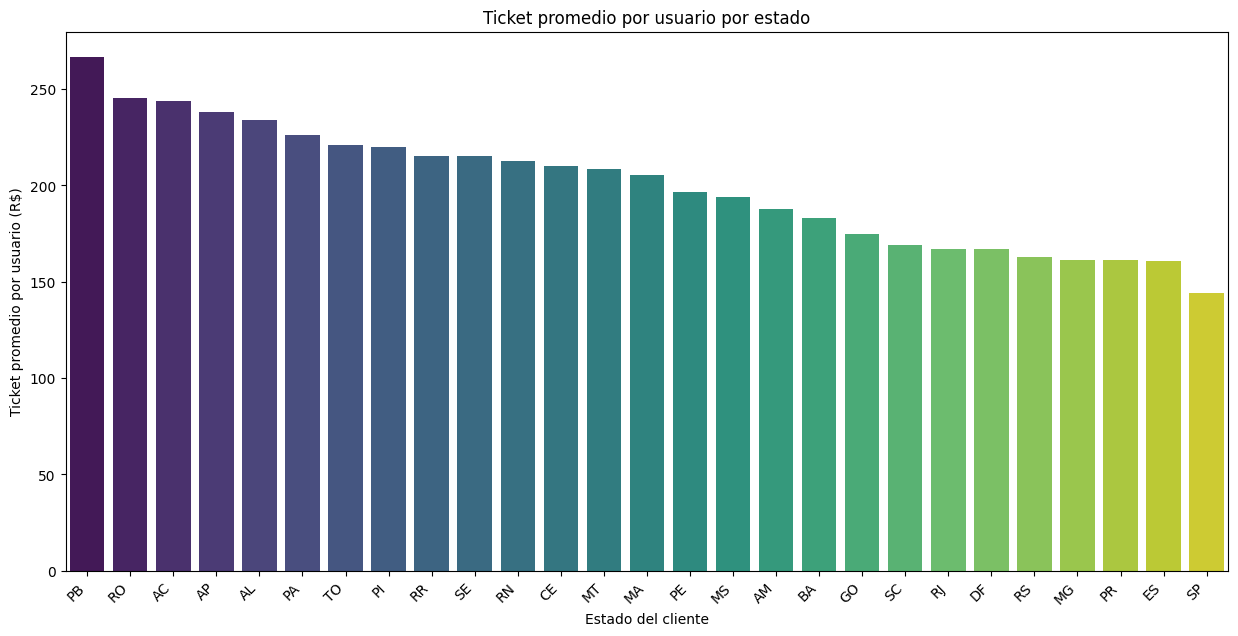

   customer_state  ticket_promedio_usuario
14             PB               266.485592
20             RO               245.590524
0              AC               243.616104
   customer_state  ticket_promedio_usuario
17             PR               161.247078
7              ES               160.760094
25             SP               143.965601


In [98]:
ticket_usuario = df_orders_payments.groupby(['customer_state', 'customer_unique_id'])['payment_value'].mean().reset_index()
ticket_usuario_estado = ticket_usuario.groupby('customer_state')['payment_value'].mean().reset_index()
ticket_usuario_estado = ticket_usuario_estado.rename(columns={'payment_value': 'ticket_promedio_usuario'})
ticket_usuario_estado = ticket_usuario_estado.sort_values('ticket_promedio_usuario', ascending=False)

plt.figure(figsize=(15, 7))
sns.barplot(x='customer_state', y='ticket_promedio_usuario', hue='customer_state',
            data=ticket_usuario_estado, palette='viridis', legend=False)
plt.title('Ticket promedio por usuario por estado')
plt.xlabel('Estado del cliente')
plt.ylabel('Ticket promedio por usuario (R$)')
plt.xticks(rotation=45, ha='right')
plt.show()

print(ticket_usuario_estado.head(3))
print(ticket_usuario_estado.tail(3))

Resultado: Paraíba (PB) tiene el ticket promedio por usuario más alto (R$ 266), seguido por Rondônia (RO) y Acre (AC), con alrededor de R$ 245. São Paulo (SP) tiene el más bajo (R$ 144). El valor pagado incluye el flete, y el flete promedio por ítem es de unos R$ 43 en Paraíba frente a R$ 15 en São Paulo, por lo que parte de la diferencia se explica por los costos de envío a estados más lejanos.